In [1]:
import sys; sys.path.append("..")
import numpy as np, matplotlib.pyplot as plt
from data import get_splits, one_hot
from mlp import MLP, train_mlp, eval_loss_acc

d = get_splits()
Xtr, ytr, Xva, yva = d["X_train"], d["y_train"], d["X_val"], d["y_val"]

# Kiểm tra 1: kích thước gradient trùng kích thước tham số, loss khởi đầu gần ln(10)
net = MLP(seed=0)
X, Y = Xtr[:256], one_hot(ytr[:256])
loss, g = net.loss_and_grads(X, Y)
for k in ["W1", "b1", "W2", "b2"]:
    print(k, getattr(net, k).shape, g[k].shape, getattr(net, k).shape == g[k].shape)
print("loss khởi đầu:", loss, "| ln(10) =", np.log(10))     # khoảng 2.3 đến 2.6

# Kiểm tra 2: overfit 100 mẫu. Mạng đúng thì loss phải về gần 0 và accuracy 100%
net = MLP(seed=0)
X, Y, y = Xtr[:100], one_hot(ytr[:100]), ytr[:100]
for step in range(500):
    loss, g = net.loss_and_grads(X, Y)
    net.apply(g, 0.1)
    if step % 100 == 0: print(step, round(float(loss), 4))
print("loss cuối:", loss, "| acc:", (net.predict(X) == y).mean())

W1 (784, 128) (784, 128) True
b1 (128,) (128,) True
W2 (128, 10) (128, 10) True
b2 (10,) (10,) True
loss khởi đầu: 2.4387121 | ln(10) = 2.302585092994046
0 2.4311
100 0.0734
200 0.0273
300 0.0158
400 0.0109
loss cuối: 0.00821106 | acc: 1.0


In [2]:
rng = np.random.default_rng(0)
idx = rng.choice(len(Xtr), 20, replace=False)
X = Xtr[idx].astype(np.float64); Y = one_hot(ytr[idx]).astype(np.float64)

net = MLP(n_hidden=32, seed=1, dtype=np.float64)
net.b1 = rng.standard_normal(32) * 0.1        # bias khác 0 để kiểm tra bias thật sự
net.b2 = rng.standard_normal(10) * 0.1

def grad_check(l2, n=300, eps=1e-5):
    _, grads = net.loss_and_grads(X, Y, l2)
    for name in ["W1", "b1", "W2", "b2"]:
        P, G = getattr(net, name), grads[name]
        errs = []
        for k in rng.choice(P.size, min(n, P.size), replace=False):
            i = np.unravel_index(k, P.shape)
            old = P[i]
            P[i] = old + eps; lp = net.loss_and_grads(X, Y, l2)[0]
            P[i] = old - eps; lm = net.loss_and_grads(X, Y, l2)[0]
            P[i] = old
            num, ana = (lp - lm) / (2 * eps), G[i]
            if abs(num) + abs(ana) > 1e-8:             # bỏ qua các phần tử cả hai đều bằng 0
                errs.append(abs(num - ana) / (abs(num) + abs(ana)))
        print(f"l2={l2} {name}: sai số tương đối tối đa {max(errs):.2e} (trên {len(errs)} phần tử)")

grad_check(l2=0.0)
grad_check(l2=0.1)

l2=0.0 W1: sai số tương đối tối đa 1.07e-07 (trên 124 phần tử)
l2=0.0 b1: sai số tương đối tối đa 1.71e-08 (trên 31 phần tử)
l2=0.0 W2: sai số tương đối tối đa 1.35e-07 (trên 290 phần tử)
l2=0.0 b2: sai số tương đối tối đa 2.78e-10 (trên 10 phần tử)
l2=0.1 W1: sai số tương đối tối đa 7.25e-06 (trên 300 phần tử)
l2=0.1 b1: sai số tương đối tối đa 7.88e-08 (trên 31 phần tử)
l2=0.1 W2: sai số tương đối tối đa 6.89e-08 (trên 300 phần tử)
l2=0.1 b2: sai số tương đối tối đa 8.72e-10 (trên 10 phần tử)


In [3]:
from metrics import evaluate, Timer
net = MLP(n_hidden=128, seed=0)
with Timer() as t_fit:
    hist = train_mlp(net, Xtr, ytr, Xva, yva, lr=0.1, epochs=20, batch_size=128)
print("epoch  train_loss  val_loss  val_acc")
for ep in range(20):
    print(ep + 1, round(hist["train_loss"][ep], 4), round(hist["val_loss"][ep], 4), round(hist["val_acc"][ep] * 100, 2))
print(f"thời gian (có ghi loss): {t_fit.seconds:.1f}s")

epoch  train_loss  val_loss  val_acc
1 0.3122 0.3277 90.59
2 0.2255 0.2446 93.1
3 0.191 0.212 93.98
4 0.1711 0.193 94.5
5 0.1457 0.1679 95.36
6 0.1304 0.155 95.71
7 0.1254 0.1512 95.88
8 0.1116 0.139 96.17
9 0.0989 0.1274 96.4
10 0.092 0.1223 96.57
11 0.0871 0.1181 96.67
12 0.0822 0.1153 96.73
13 0.0742 0.1096 96.92
14 0.0703 0.1069 96.94
15 0.0696 0.1072 96.98
16 0.0635 0.1022 97.08
17 0.0597 0.0999 97.1
18 0.0553 0.097 97.19
19 0.0539 0.0961 97.2
20 0.0534 0.0996 97.19
thời gian (có ghi loss): 10.7s


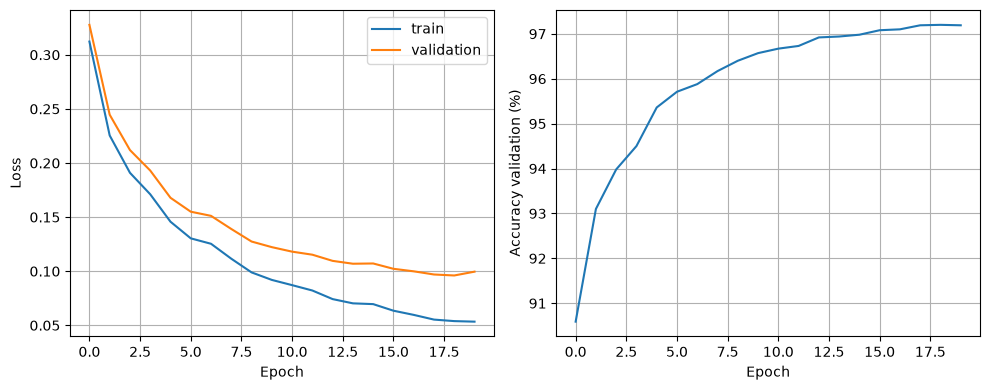

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["val_loss"], label="validation")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend(); ax[0].grid(True)
ax[1].plot(np.array(hist["val_acc"]) * 100); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy validation (%)"); ax[1].grid(True)
plt.tight_layout(); plt.savefig("../report/mlp_curves.png", dpi=150); plt.show()

In [7]:
def make_check_net(l2_seed=1):
    r = np.random.default_rng(0)
    idx = r.choice(len(Xtr), 20, replace=False)
    Xc = Xtr[idx].astype(np.float64); Yc = one_hot(ytr[idx]).astype(np.float64)
    n = MLP(n_hidden=32, seed=l2_seed, dtype=np.float64)
    n.b1 = r.standard_normal(32) * 0.1
    n.b2 = r.standard_normal(10) * 0.1
    return n, Xc, Yc

def worst_rel2(l2, name="W1", n_el=300, eps=1e-5, seed=0):
    net_c, Xc, Yc = make_check_net()
    assert net_c.W1.dtype == np.float64
    r = np.random.default_rng(seed)
    _, grads = net_c.loss_and_grads(Xc, Yc, l2)
    P, G = getattr(net_c, name), grads[name]
    best_rel, info = 0.0, None
    for k in r.choice(P.size, min(n_el, P.size), replace=False):
        i = np.unravel_index(k, P.shape)
        old = P[i]
        P[i] = old + eps; lp = net_c.loss_and_grads(Xc, Yc, l2)[0]
        P[i] = old - eps; lm = net_c.loss_and_grads(Xc, Yc, l2)[0]
        P[i] = old
        num, ana = (lp - lm) / (2 * eps), G[i]
        if abs(num) + abs(ana) > 1e-8:
            rel = abs(num - ana) / (abs(num) + abs(ana))
            if rel > best_rel:
                best_rel, info = rel, (abs(num - ana), abs(ana))
    return best_rel, info

for seed in range(5):
    rel, (abs_err, g) = worst_rel2(0.1, seed=seed)
    print(f"seed {seed}: rel {rel:.2e} | sai số tuyệt đối {abs_err:.2e} | |gradient| {g:.2e}")

seed 0: rel 2.80e-07 | sai số tuyệt đối 2.67e-11 | |gradient| 4.77e-05
seed 1: rel 8.16e-07 | sai số tuyệt đối 5.37e-11 | |gradient| 3.29e-05
seed 2: rel 3.99e-07 | sai số tuyệt đối 2.09e-11 | |gradient| 2.62e-05
seed 3: rel 5.53e-07 | sai số tuyệt đối 5.16e-11 | |gradient| 4.67e-05
seed 4: rel 4.72e-07 | sai số tuyệt đối 3.67e-11 | |gradient| 3.89e-05
